<a href="https://colab.research.google.com/github/harshpp707/BIOL5340-Cancer-RNASeq-Feature-Selection/blob/main/notebooks/01_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Data preparation and exploratory analysis
**Project:** Evaluating feature selection methods for cancer classification using RNA-seq data  
**Authors:** Harsh Patel, Omkar Juvatkar, Pritesh Das

**Goal:** Download/verify the UCI RNA-seq dataset, inspect labels and missingness, save reusable copies and a fixed stratified holdout. PCA is for descriptive visualization only; it is not used for supervised feature selection here.

Source: [UCI dataset 401](https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq);

In [1]:
!pip -q install ucimlrepo

In [7]:
from pathlib import Path
import urllib.request
import zipfile
import tarfile
import shutil
from google.colab import drive
import json, platform, sys
import numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [8]:
DATA_DIR = Path(
    "/content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project/data"
)
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
zip_path = DATA_DIR / "cancer_rnaseq.zip"

# Download only once
if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)
    print("Dataset downloaded successfully.")

# Extract CSV files from the nested archive
if not all((DATA_DIR / f).exists() for f in ["data.csv", "labels.csv"]):
    with zipfile.ZipFile(zip_path) as zf:
        tar_name = next(
            name for name in zf.namelist()
            if name.endswith(".tar.gz")
        )

        with zf.open(tar_name) as nested:
            with tarfile.open(fileobj=nested, mode="r|gz") as tar:
                for member in tar:
                    filename = Path(member.name).name
                    if filename in {"data.csv", "labels.csv"}:
                        with tar.extractfile(member) as src:
                            with open(DATA_DIR / filename, "wb") as dst:
                                shutil.copyfileobj(src, dst)

print("Dataset files are ready:", list(DATA_DIR.glob("*.csv")))

Dataset downloaded successfully.
Dataset files are ready: [PosixPath('/content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project/data/data.csv'), PosixPath('/content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project/data/labels.csv')]


In [9]:
SEED = 42

X = pd.read_csv(DATA_DIR / "data.csv", index_col=0)
labels = pd.read_csv(DATA_DIR / "labels.csv", index_col=0)

# Match labels to sample IDs
y = labels.iloc[:, 0].reindex(X.index)

print("Shape:", X.shape)
print("Labels:", y.shape)
print("\nClasses:\n", y.value_counts())
print("\nMissing expression cells:", X.isna().sum().sum())
print("Duplicate samples:", X.index.duplicated().sum())

assert X.shape == (801, 20531)
assert len(y) == len(X)
assert not X.isna().any().any()
assert not y.isna().any()

Shape: (801, 20531)
Labels: (801,)

Classes:
 Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Missing expression cells: 0
Duplicate samples: 0


In [10]:
X.to_pickle(DATA/'X_expression.pkl')
y.rename('cancer_type').to_csv(DATA/'y_labels.csv',index=False)
train_idx,test_idx = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y,
                                      random_state=SEED)
np.save(DATA/'train_indices.npy',train_idx)
np.save(DATA/'test_indices.npy',test_idx)
print('Training samples:',len(train_idx),'Test samples:',len(test_idx))
print('Training labels:\n',y.iloc[train_idx].value_counts())
print('Test labels:\n',y.iloc[test_idx].value_counts())
metadata = {'source':'UCI dataset 401','doi':'10.24432/C5R88H',
            'seed':SEED,'test_fraction':0.2,'train_n':len(train_idx),'test_n':len(test_idx),
            'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
            'scikit_learn':sklearn.__version__}
(DATA/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2))

Training samples: 640 Test samples: 161
Training labels:
 Class
BRCA    240
KIRC    116
LUAD    113
PRAD    109
COAD     62
Name: count, dtype: int64
Test labels:
 Class
BRCA    60
KIRC    30
LUAD    28
PRAD    27
COAD    16
Name: count, dtype: int64


225

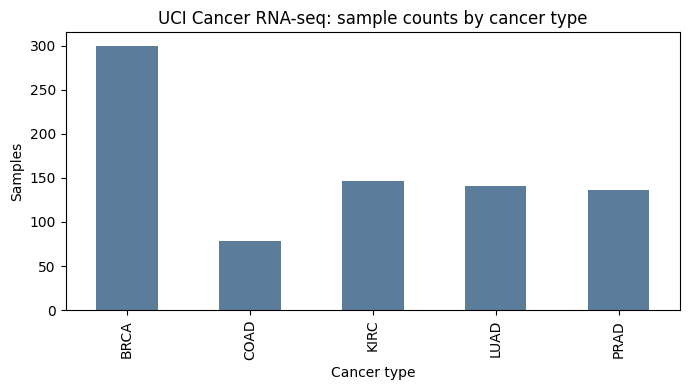

In [11]:
counts=y.value_counts().sort_index()
ax=counts.plot(kind='bar',figsize=(7,4),color='#5B7C9A')
ax.set(title='UCI Cancer RNA-seq: sample counts by cancer type', xlabel='Cancer type',ylabel='Samples')
plt.tight_layout(); plt.savefig(FIGURES/'class_distribution.png',dpi=180); plt.show()

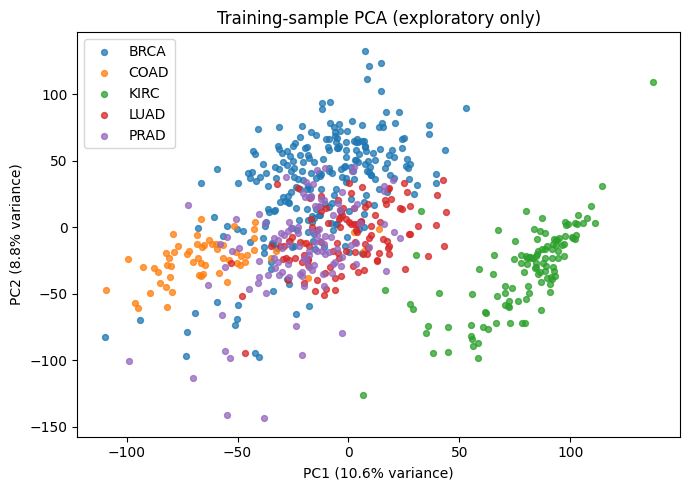

In [12]:
scaler=StandardScaler()
Xtrain_scaled=scaler.fit_transform(X.iloc[train_idx].to_numpy(dtype=np.float32))
pca=PCA(n_components=2,random_state=SEED)
z=pca.fit_transform(Xtrain_scaled)
plt.figure(figsize=(7,5))
for cls in sorted(y.unique()):
    mask=(y.iloc[train_idx].to_numpy()==cls)
    plt.scatter(z[mask,0],z[mask,1],s=18,alpha=0.75,label=cls)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title('Training-sample PCA (exploratory only)'); plt.legend(); plt.tight_layout()
plt.savefig(FIGURES/'pca_training_only.png',dpi=180);plt.show()